Parse events.jsonl and get energy consumption

In [1]:
import json
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.dates as mdates

In [196]:
lines = []
with open(pathlib.Path("..") / "events.xps.jsonl") as f:
    for line in f.readlines():
        lines.append(json.loads(line))

In [200]:
import datetime
def get_power(line):
    try:
        delta = line["codecarbon"]["delta"]
        return delta["cpu_power"] + delta["gpu_power"] + delta["ram_power"]
    except:
        return 0

def get_power_tasmota(line):
    try:
        return line["tasmota"]["data"]["Power"]        
    except:
        return 0


timeline_data = [
    (
        datetime.datetime.fromisoformat(l["timestamp"]), 
        l.get("step", ""),
        get_power(l),
        get_power_tasmota(l),
    )
    for l in lines
]

timeline_data[10]


(datetime.datetime(2024, 12, 22, 17, 11, 46, 737455),
 'baseline',
 21.25883715062042,
 25.0)

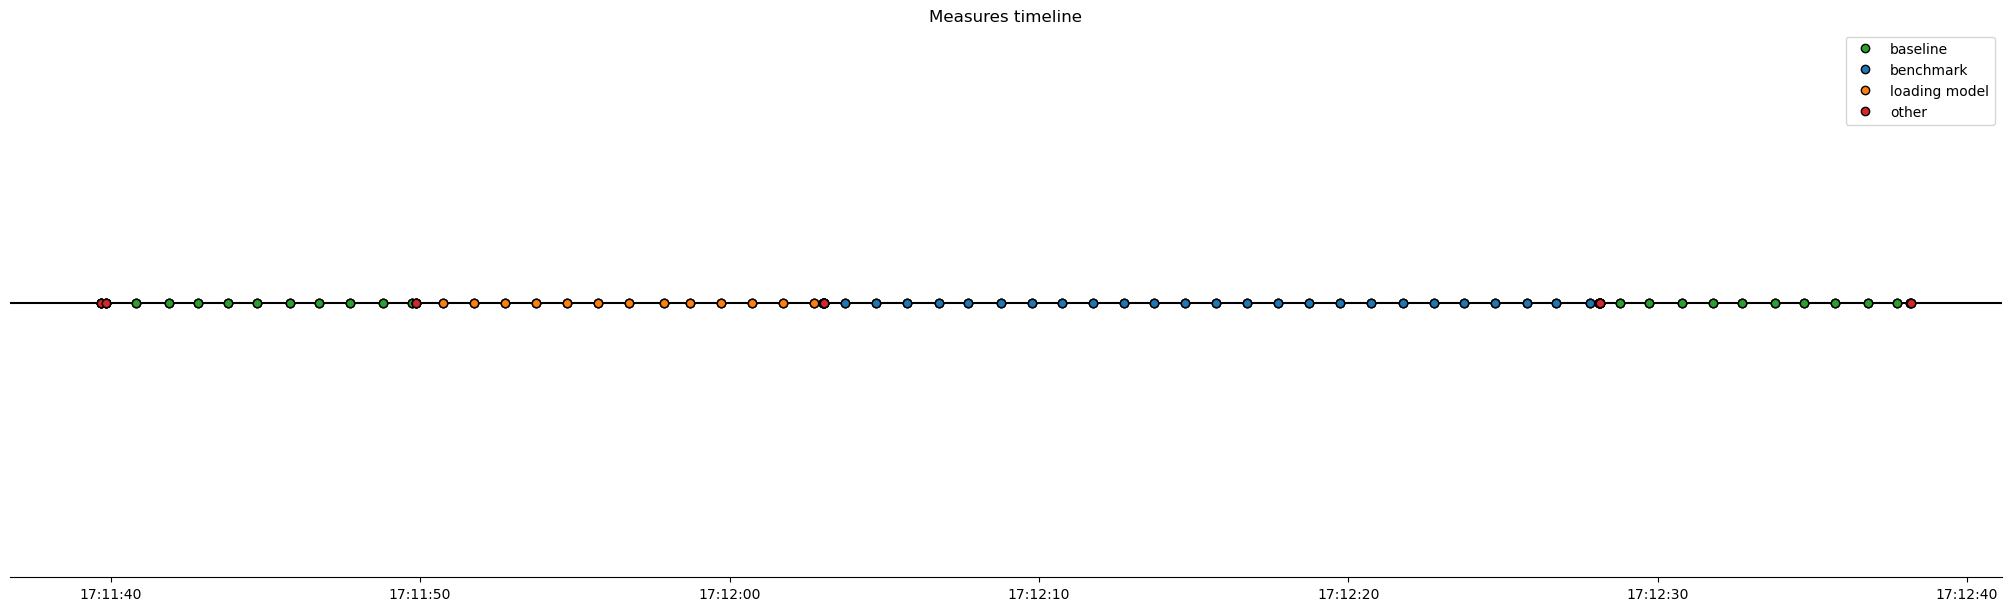

In [198]:
fig, ax = plt.subplots(figsize=(20, 6), layout="constrained")
ax.set(title="Measures timeline")
ax.axhline(0, c="black")


# baseline
baseline_data = [x for x in timeline_data if x[1] == "baseline"]
ax.plot([x[0] for x in baseline_data], np.zeros_like(baseline_data), "ko", mfc="tab:green",  label="baseline")

# measures
measures_data = [x for x in timeline_data if x[1] == "benchmark"]
ax.plot([x[0] for x in measures_data], np.zeros_like(measures_data), "ko", mfc="tab:blue", label="benchmark")

# loading
loading_data = [x for x in timeline_data if x[1] == "loading"]
ax.plot([x[0] for x in loading_data], np.zeros_like(loading_data), "ko", mfc="tab:orange", label="loading model")

# other
other_data = [x for x in timeline_data if x[1] == ""]
ax.plot([x[0] for x in other_data], np.zeros_like(other_data), "ko", mfc="tab:red", label="other")


ax.yaxis.set_visible(False)
ax.spines[["left", "top", "right"]].set_visible(False)

ax.margins(y=0.1)

# remove dupes
handles, labels = plt.gca().get_legend_handles_labels()
labels, handles = list(zip(*    list((dict(zip(labels, handles)).items()))))

plt.legend(handles, labels)
plt.show()

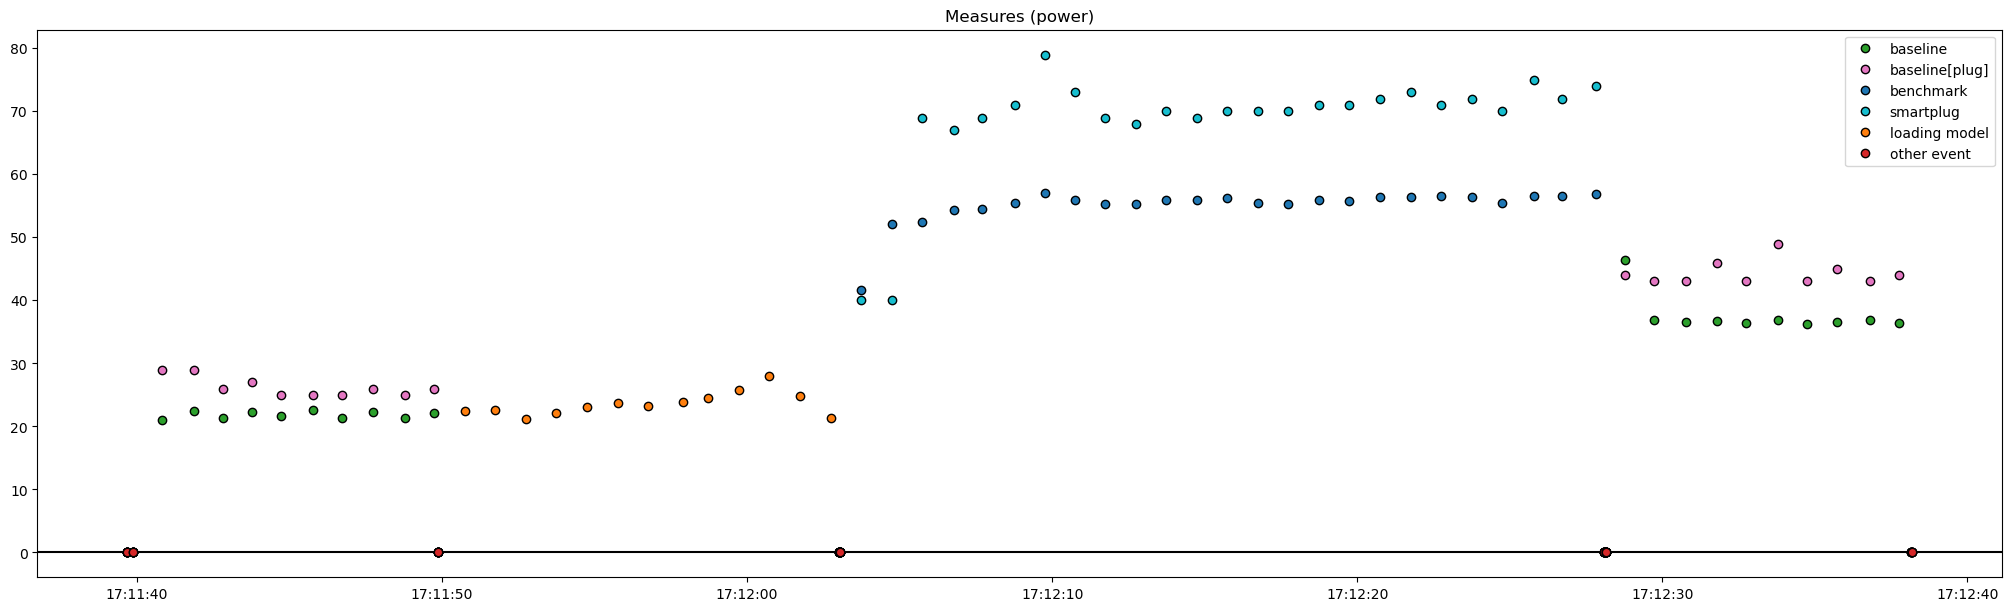

In [210]:
fig, ax = plt.subplots(figsize=(20, 6), layout="constrained")
ax.set(title="Measures (power)")
ax.axhline(0, c="black")

# baseline
baseline_data = [x for x in timeline_data if x[1] == "baseline"]
ax.plot([x[0] for x in baseline_data], 
        [x[2] for x in baseline_data], 
        "ko", mfc="tab:green",  label="baseline")


# baseline [smart plug]
baseline_data = [x for x in timeline_data if x[1] == "baseline"]
ax.plot([x[0] for x in baseline_data], 
        [x[3] for x in baseline_data], 
        "ko", mfc="tab:pink",  label="baseline[plug]")

# measures
measures_data = [x for x in timeline_data if x[1] == "benchmark"]
ax.plot([x[0] for x in measures_data], 
        [x[2] for x in measures_data], 
        "ko", mfc="tab:blue", label="benchmark")

# smart plug
measures_data = [x for x in timeline_data if x[1] == "benchmark"]
ax.plot([x[0] for x in measures_data], 
        [x[3] for x in measures_data], 
        "ko", mfc="tab:cyan", label="smartplug")

# loading
loading_data = [x for x in timeline_data if x[1] == "loading"]
ax.plot([x[0] for x in loading_data], 
        [x[2] for x in loading_data], 
        "ko", mfc="tab:orange", label="loading model")

# other
other_data = [x for x in timeline_data if x[1] == ""]
ax.plot([x[0] for x in other_data], 
        np.zeros_like(other_data), 
        "ko", mfc="tab:red", label="other event")

# remove dupes
handles, labels = plt.gca().get_legend_handles_labels()
labels, handles = list(zip(*    list((dict(zip(labels, handles)).items()))))

plt.legend(handles, labels)
#plt.show()
plt.savefig("2024-12-22.xps.smoll.png")


In [209]:
#

<module 'matplotlib.pyplot' from '/usr/lib/python3.12/site-packages/matplotlib/pyplot.py'>

# Compute energy consumed

We just use the average power minus the baseline

In [211]:
# get average baseline power
# use all baseline points ; we assume the baseline is the same before and after the inference (not quite true)
baseline_data = [get_power(l) for l in lines if l.get("step") == "baseline"]
baseline_power = sum(baseline_data)/len(baseline_data)
print(f"{baseline_power=}")

# inference duration
inference_start = datetime.datetime.fromisoformat([l for l in lines if l["message"] ==  'Starting tracker [inference]'][0]["timestamp"])
inference_stop = datetime.datetime.fromisoformat([l for l in lines if l["message"] ==  'Benchmarking finished'][0]["timestamp"])
inference_duration_s = (inference_stop-inference_start).total_seconds()
print(f"{inference_duration_s=}")


# power use during inference
inference_data = [get_power(l) for l in lines if l.get("step") == "benchmark"]
inference_power = sum(inference_data)/len(inference_data)
print(f"{inference_power=}")

# energy use
energy_use = ( inference_power - baseline_power ) * inference_duration_s
print(f"{energy_use=} J")

# per inference
num_inferences =  [l for l in lines if l.get("step") == "baseline"][0]["context"]["num_inferences"]
print(f"=> {energy_use/num_inferences=} J per inference")

# per token
num_tokens =  [l for l in lines if l.get("step") == "baseline"][-1]["context"]["total_tokens"]
print(f"=> {energy_use/num_tokens=} J per token")

# tokens per second
print(f"=> {num_tokens/inference_duration_s=} tokens per second")


baseline_power=29.715004940901736
inference_duration_s=25.100817
inference_power=55.015047558169016
energy_use=635.051739828227 J
=> energy_use/num_inferences=63.505173982822704 J per inference
=> energy_use/num_tokens=0.635051739828227 J per token
=> num_tokens/inference_duration_s=39.83934068759595 tokens per second


In [191]:
# device
[l for l in lines if l.get("step") == "benchmark"][-1]["context"]

{'num_inferences': 10, 'total_tokens': 900, 'device': 'cuda:0'}

# stats for multiple runs

In [47]:
import matplotlib
import json
import sys
import pandas as pd
import os
import pathlib
import glob

In [51]:
lib_path = str(pathlib.Path("..").resolve())
if not lib_path in sys.path:
    sys.path.append(lib_path)
import commands.results

In [53]:
import glob
files = glob.glob(str(pathlib.Path("..").resolve())+ "/data/*/*.jsonl")

In [ ]:
import json
def get_results(filename):
    results = commands.results._parse_results(filename)
    with open(filename) as f:
        while True:
            try:
                context = json.loads(next(f))["context"]
                break
            except:
                ...
    return {**context, **results}


data = [get_results(filename) for filename in files]

In [55]:
import pandas as pd
df = pd.DataFrame(data)
df.head(4)

,num_inferences,hostname,bench,model,energy,energy_per_token,energy_per_inference,inference_time,num_tokens,total_tokens,device
0,100,fenris,smollm2-135m,HuggingFaceTB/SmolLM2-135M,37088.346670,3.708835,370.883467,354.859695,10000,NaN,NaN
1,100,fenris,smollm2-135m,HuggingFaceTB/SmolLM2-360M,79503.653223,7.950365,795.036532,751.151927,10000,10000.0,cpu
2,100,osiris,smollm2-135m,HuggingFaceTB/SmolLM2-135M,22611.259746,2.261126,226.112597,85.520291,10000,NaN,NaN
3,100,osiris,smollm2-135m,HuggingFaceTB/SmolLM2-360M,27259.509300,2.725951,272.595093,92.734021,10000,10000.0,cuda:0


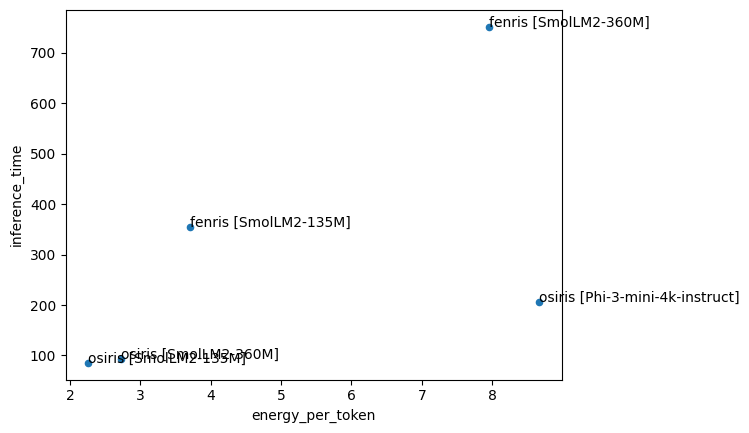

In [41]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
x = "energy_per_token"
y = "inference_time"
df.plot(x=x, y=y, kind="scatter", ax=ax)

for k, v in df.iterrows():
    model = v["model"].split("/")[-1]
    ax.annotate(f"{v['hostname']} [{model}]", (v[x], v[y]))